# Project 07: Healthcare Readmission & Patient Flow Analysis

Tools: Python, Pandas, NumPy and Matplotlib

Project Overview

This project is about looking at hospital patient episodes using a diabetes dataset. It's all about patient flow, length of stay, readmissions and the various other healthcare related aspects.

Dataset

The analysis is based on the UCI Diabetes 130 US Hospitals dataset (1999-2008) which contains de-identified hospital encounter data.

Objectives

Analyse hospital admission and discharge patterns.
Study the length of hospital stays.
Examine patient readmission rates.
Identify patterns via data analysis and visualisation. Note: This project is for educational and descriptive purposes only and is not intended for clinical diagnosis or treatment decisions.


Project Submitted By: Utkarsh Yadav

Branch: CSE AI & ML

Section: AIML-6

Admission No.: 2026B15310064

## 1) Load Data

We first load the Diabetes hospital data set.

This data set contains hospital encounters from 130 hospitals in the USA between 1999 and 2008. We can use this to look at the admission rates, duration of stays and re-admission rates within the hospitals.

We load the data in as a pandas data frame so that we can easily view, clean and analyse the data.

In [39]:
import os
import zipfile
import urllib.request
import shutil
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 100)

file_name = 'diabetic_data.csv'
archive_name = 'diabetes_130_us_hospitals.zip'
url = 'https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip'

if not os.path.exists(file_name):
    print('Downloading the official UCI dataset...')
    urllib.request.urlretrieve(url, archive_name)
    with zipfile.ZipFile(archive_name) as z:
        candidates = [n for n in z.namelist() if n.lower().endswith('diabetic_data.csv')]
        if not candidates:
            raise FileNotFoundError('diabetic_data.csv was not found in the downloaded archive.')
        with z.open(candidates[0]) as src, open(file_name, 'wb') as dst:
            shutil.copyfileobj(src, dst)
    print('Created:', file_name)

raw = pd.read_csv(file_name, low_memory=False)
print('Rows (encounters):', len(raw))
print('Columns:', len(raw.columns))
display(raw.head())

Rows (encounters): 101766
Columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Understanding the data

Each row represents an individual hospital encounter. Each individual encounter is assigned an ID with encounter_id. However, encounters with the same patient (de-identified) can be found by using patient_nbr.

For `readmitted`, we have:

`<30` – readmitted within 30 days

`>30` – readmitted after 30 days

`NO` – not readmitted

In this project we will use these categories to understand patterns in readmission. We do not need to work out the dates of readmissions in this case.

In [40]:
print('Dataset shape:', raw.shape)
print('Unique encounters:', raw['encounter_id'].nunique())
print('Unique patients:', raw['patient_nbr'].nunique())
print('Duplicate encounter IDs:', raw['encounter_id'].duplicated().sum())
print('Readmission categories:')
display(raw['readmitted'].value_counts(dropna=False).to_frame('encounters'))
print('Column names:')
print(raw.columns.tolist())

Dataset shape: (101766, 50)
Unique encounters: 101766
Unique patients: 71518
Duplicate encounter IDs: 0
Readmission categories:


,encounters
readmitted,
NO,54864
>30,35545
<30,11357


Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


## 3.Checking data quality

First we will check that there are no missing values, duplicated data, unique variables and invalid values in the dataset.

Within this dataset, unknown/missing categorical values have been denoted by a `?`. Therefore, these values were changed to `NaN` to make them identifiable for data cleansing.

This ensures improved reliability within the dataset.

In [41]:
audit = raw.copy()
audit = audit.replace('?', np.nan)

missing = audit.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(audit) * 100).round(2)
missing_table = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate encounter IDs:', raw['encounter_id'].duplicated().sum())
display(missing_table.head(20))
print('Unique readmission labels:', raw['readmitted'].dropna().unique())

Exact duplicate rows: 0
Duplicate encounter IDs: 0


,missing_count,missing_pct
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
patient_nbr,0,0.00


Unique readmission labels: ['NO' '>30' '<30']


## 4. Field validation

As there is no information on admission and discharge dates, we are unable to determine the order of visits and the time between re-admissions.

However, the duration of a patients hospital stay `time_in_hospital` can be determined, along with the number of inpatient, emergency and outpatient visits in previous admissions `number_inpatient`, `number_emergency`, `number_outpatient`.

These variables will be used within further analysis despite the absence of specific date information.

In [42]:
df = audit.copy()
numeric_cols = [
    'encounter_id', 'patient_nbr', 'admission_type_id',
    'discharge_disposition_id', 'admission_source_id',
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

df['readmitted'] = df['readmitted'].astype('string').str.strip()
df['age'] = df['age'].astype('string').str.strip()

print('Invalid/missing encounter IDs:', df['encounter_id'].isna().sum())
print('Invalid/missing patient IDs:', df['patient_nbr'].isna().sum())
print('Missing/non-positive length of stay:',
      (df['time_in_hospital'].isna() | (df['time_in_hospital'] <= 0)).sum())
print('Missing/non-numeric prior inpatient visits:',
      df['number_inpatient'].isna().sum())
print('Readmission labels:', df['readmitted'].dropna().unique())

Invalid/missing encounter IDs: 0
Invalid/missing patient IDs: 0
Missing/non-positive length of stay: 0
Missing/non-numeric prior inpatient visits: 0
Readmission labels: <StringArray>
['NO', '>30', '<30']
Length: 3, dtype: string


## 5.Data Cleaning

Rows with missing or invalid data in encounter ID, Patient ID, Length of stay and Readmissions have been removed.

Where possible, missing clinical data has been left in place. For group analysis, missing data has simply been defined as `Unknown`.

Duplicate rows have been removed. Only one row per encounter ID has been kept the first instance. The number of duplicates is recorded to provide a record of data cleaning.

This ensures consistency within data, and reduces redundant data.

In [43]:
before_rows = len(df)
duplicate_rows = int(df.duplicated().sum())
duplicate_encounters = int(df['encounter_id'].duplicated().sum())

clean = df.drop_duplicates().copy()
clean = clean.dropna(subset=['encounter_id', 'patient_nbr', 'time_in_hospital', 'readmitted'])
clean = clean.drop_duplicates(subset=['encounter_id'], keep='first')
clean = clean[
    clean['time_in_hospital'].between(1, 365)
    & clean['readmitted'].isin(['<30', '>30', 'NO'])
].copy()

clean['readmitted_30d'] = clean['readmitted'].eq('<30')

clean['age'] = clean['age'].fillna('Unknown')
clean['race'] = clean['race'].fillna('Unknown')
clean['gender'] = clean['gender'].fillna('Unknown')

print('Rows before cleaning:', before_rows)
print('Exact duplicate rows removed:', duplicate_rows)
print('Duplicate encounter IDs observed:', duplicate_encounters)
print('Rows after cleaning:', len(clean))
print('Rows excluded:', before_rows - len(clean))
display(clean[['encounter_id', 'patient_nbr', 'age', 'time_in_hospital', 'readmitted']].head())

Rows before cleaning: 101766
Exact duplicate rows removed: 0
Duplicate encounter IDs observed: 0
Rows after cleaning: 101766
Rows excluded: 0


,encounter_id,patient_nbr,age,time_in_hospital,readmitted
0,2278392,8222157,[0-10),1,NO
1,149190,55629189,[10-20),3,>30
2,64410,86047875,[20-30),2,NO
3,500364,82442376,[30-40),2,NO
4,16680,42519267,[40-50),1,NO


## 6.Patient flow analysis

Basic information about patient flow can be calculated.

The total patient encounters within the dataset, the number of unique patients, mean/median length of stay, and outcome of readmissions has been calculated.

It is important to note that the number of patient encounters may be greater than the number of unique patients, as patients can attend multiple times.

This gives us basic information about the activity in the hospital, and what proportion of patients were re-admitted.

In [44]:
flow_summary = pd.Series({
    'encounters': len(clean),
    'unique_patients': clean['patient_nbr'].nunique(),
    'mean_length_of_stay_days': clean['time_in_hospital'].mean(),
    'median_length_of_stay_days': clean['time_in_hospital'].median(),
    'mean_encounters_per_patient': len(clean) / clean['patient_nbr'].nunique(),
    'readmission_under_30d_pct': clean['readmitted_30d'].mean() * 100
}).to_frame('value').round(2)

outcome_counts = clean['readmitted'].value_counts().rename_axis('outcome').to_frame('encounters')
outcome_counts['percent'] = (outcome_counts['encounters'] / len(clean) * 100).round(2)

display(flow_summary)
display(outcome_counts)

,value
encounters,101766.00
unique_patients,71518.00
mean_length_of_stay_days,4.40
median_length_of_stay_days,4.00
mean_encounters_per_patient,1.42
readmission_under_30d_pct,11.16


,encounters,percent
outcome,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


## 7. Hospital Length of Stay and Patient Frequency

The length of stay for each type of readmission has been compared.

The frequency of individual patients in the dataset has been examined, as some patients have multiple hospital visits.

This analysis provides an insight into links between length of hospital stay, number of visits and readmission type. However, it does not definitively prove that a longer length of hospital stay causes readmissions.

In [45]:
los_by_outcome = clean.groupby('readmitted')['time_in_hospital'].agg(
    encounters='count', mean_los='mean', median_los='median',
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
).round(2)

encounters_per_patient = clean.groupby('patient_nbr').size().rename('encounters')
frequency_summary = encounters_per_patient.value_counts().sort_index().rename_axis(
    'encounters_per_patient'
).to_frame('number_of_patients')

display(los_by_outcome)
display(frequency_summary.head(15))

,encounters,mean_los,median_los,q1,q3
readmitted,,,,,
<30,11357,4.77,4.0,2.0,6.0
>30,35545,4.50,4.0,2.0,6.0
NO,54864,4.25,3.0,2.0,6.0


,number_of_patients
encounters_per_patient,
1,54745
2,10434
3,3328
4,1421
5,717
6,346
7,207
8,111
9,70


## 8.Readmission within different categories

Proportion of encounters in the `<30` category (readmission within 30 days), with a note that groups containing less than 100 encounters should be interpreted with caution. The categories for age and length of stay have been created for description only, and do not represent risk factors.

In [46]:
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)',
             '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)', 'Unknown']
clean['age_band'] = pd.Categorical(clean['age'], categories=age_order, ordered=True)

clean['los_band'] = pd.cut(
    clean['time_in_hospital'],
    bins=[0, 2, 5, 10, 365],
    labels=['1-2 days', '3-5 days', '6-10 days', '11+ days']
)

def group_readmission(data, column, min_n=100):
    result = data.groupby(column, dropna=False, observed=False).agg(
        encounters=('encounter_id', 'count'),
        readmissions_under_30d=('readmitted_30d', 'sum'),
        readmission_pct=('readmitted_30d', 'mean')
    ).reset_index()
    result['readmission_pct'] = (result['readmission_pct'] * 100).round(2)
    result['small_group'] = result['encounters'] < min_n
    return result.sort_values('encounters', ascending=False)

age_readmission = group_readmission(clean, 'age_band')
los_readmission = group_readmission(clean, 'los_band')
admission_type_readmission = group_readmission(clean, 'admission_type_id')
admission_source_readmission = group_readmission(clean, 'admission_source_id')

display(age_readmission)
display(los_readmission)
display(admission_type_readmission.head(15))
display(admission_source_readmission.head(15))

,age_band,encounters,readmissions_under_30d,readmission_pct,small_group
7,[70-80),26068,3069,11.77,False
6,[60-70),22483,2502,11.13,False
5,[50-60),17256,1668,9.67,False
8,[80-90),17197,2078,12.08,False
4,[40-50),9685,1027,10.6,False
3,[30-40),3775,424,11.23,False
9,[90-100),2793,310,11.1,False
2,[20-30),1657,236,14.24,False
1,[10-20),691,40,5.79,False
0,[0-10),161,3,1.86,False


,los_band,encounters,readmissions_under_30d,readmission_pct,small_group
1,3-5 days,41646,4737,11.37,False
0,1-2 days,31432,2874,9.14,False
2,6-10 days,23133,3074,13.29,False
3,11+ days,5555,672,12.1,False


,admission_type_id,encounters,readmissions_under_30d,readmission_pct,small_group
0,1,53990,6221,11.52,False
2,3,18869,1961,10.39,False
1,2,18480,2066,11.18,False
5,6,5291,586,11.08,False
4,5,4785,495,10.34,False
7,8,320,27,8.44,False
6,7,21,0,0.0,True
3,4,10,1,10.0,True


,admission_source_id,encounters,readmissions_under_30d,readmission_pct,small_group
6,7,57494,6720,11.69,False
0,1,29565,3130,10.59,False
13,17,6781,706,10.41,False
3,4,3187,309,9.7,False
5,6,2264,212,9.36,False
1,2,1104,111,10.05,False
4,5,855,101,11.81,False
2,3,187,29,15.51,False
14,20,161,22,13.66,False
8,9,125,13,10.4,False


## 9.Past Visits

### Previous hospital attendance

We can explore previous hospital attendances by looking at the number of inpatient, emergency and out-patient visits for patients.

We can look at how many previous visits each patient had, and see if there is a correlation with the readmission status (within 30 days: `<30`).

Due to missing information on inpatient admittance and discharge dates, we simply look at total numbers. We cannot determine any pattern in the data by month, nor the time since previous visits.

In [47]:
utilisation_cols = ['number_inpatient', 'number_emergency', 'number_outpatient']
utilisation_summary = clean.groupby('readmitted')[utilisation_cols].agg(['mean', 'median']).round(2)
display(utilisation_summary)

clean['prior_inpatient_band'] = pd.cut(
    clean['number_inpatient'].fillna(0),
    bins=[-1, 0, 1, 2, 1000],
    labels=['0', '1', '2', '3+']
)
prior_inpatient_readmission = group_readmission(clean, 'prior_inpatient_band')
display(prior_inpatient_readmission)

number_inpatient        number_emergency        number_outpatient  \
                       mean median             mean median              mean   
readmitted                                                                     
<30                    1.22    0.0             0.36    0.0              0.44   
>30                    0.84    0.0             0.28    0.0              0.50   
NO                     0.38    0.0             0.11    0.0              0.27   

                   
           median  
readmitted         
<30           0.0  
>30           0.0  
NO            0.0

,prior_inpatient_band,encounters,readmissions_under_30d,readmission_pct,small_group
0,0,67630,5706,8.44,False
1,1,19521,2523,12.92,False
2,2,7566,1319,17.43,False
3,3+,7049,1809,25.66,False


## 10. Missingness, coding and fairness audit

Missing data. Compare readmission rates between different racial and gender groups. Racial and gender categories may have missing data, or inconsistent coding. Differences in outcomes between these groups should not be interpreted as biological differences between people in these groups. They must not be used to imply ranking of individuals. Groups with few members should be excluded.

In [48]:
missing_clean = clean.isna().sum().sort_values(ascending=False)
missing_clean_pct = (missing_clean / len(clean) * 100).round(2)
missing_clean_table = pd.DataFrame({
    'missing_count': missing_clean,
    'missing_pct': missing_clean_pct
})
display(missing_clean_table.head(20))

race_readmission = group_readmission(clean, 'race', min_n=200)
gender_readmission = group_readmission(clean, 'gender', min_n=200)
display(race_readmission)
display(gender_readmission)

,missing_count,missing_pct
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
age,0,0.00
gender,0,0.00


,race,encounters,readmissions_under_30d,readmission_pct,small_group
2,Caucasian,76099,8592,11.29,False
0,AfricanAmerican,19210,2155,11.22,False
5,Unknown,2273,188,8.27,False
3,Hispanic,2037,212,10.41,False
4,Other,1506,145,9.63,False
1,Asian,641,65,10.14,False


,gender,encounters,readmissions_under_30d,readmission_pct,small_group
0,Female,54708,6152,11.25,False
1,Male,47055,5205,11.06,False
2,Unknown/Invalid,3,0,0.0,True


## 11. Sensitivity checks

Robustness checks to assess sensitivity of overall proportion (<30) were performed by analysing data on encounters with a duration of length-of-stay ≥2 days, encounters within the 99th percentile of length-of-stay, and encounters where race/gender was missing. These checks do not confirm the accuracy of any estimates.

In [49]:
los_99 = clean['time_in_hospital'].quantile(0.99)
cases = {
    'All cleaned encounters': clean,
    'LOS at least 2 days': clean[clean['time_in_hospital'] >= 2],
    'Exclude LOS above 99th percentile': clean[clean['time_in_hospital'] <= los_99],
    'Known race and gender only': clean[clean['race'].ne('Unknown') & clean['gender'].notna()]
}

sensitivity_rows = []
for name, subset in cases.items():
    sensitivity_rows.append({
        'scenario': name,
        'encounters': len(subset),
        'patients': subset['patient_nbr'].nunique(),
        'readmission_under_30d_pct': subset['readmitted_30d'].mean() * 100,
        'mean_los_days': subset['time_in_hospital'].mean()
    })

sensitivity = pd.DataFrame(sensitivity_rows).round(2)
display(sensitivity)
print('99th percentile LOS cutoff:', round(los_99, 2), 'days')

,scenario,encounters,patients,readmission_under_30d_pct,mean_los_days
0,All cleaned encounters,101766,71518,11.16,4.40
1,LOS at least 2 days,87558,62506,11.64,4.95
2,Exclude LOS above 99th percentile,101766,71518,11.16,4.40
3,Known race and gender only,99493,69668,11.23,4.40


99th percentile LOS cutoff: 14.0 days


## 12. Charts (6 graphs)

The charts are saved as PNG files so they can be included in the report. Every chart includes a title, labels and units. Patient identifiers are not plotted.

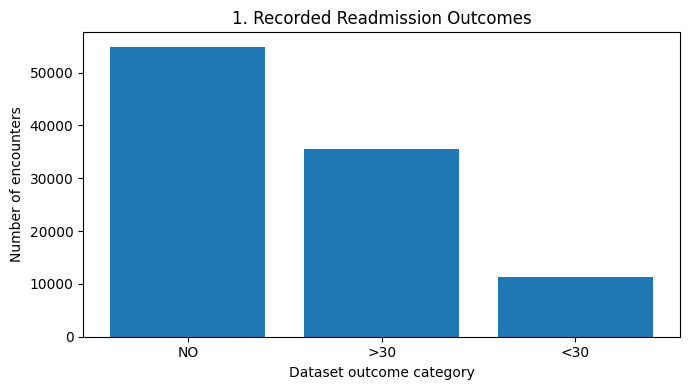

In [50]:
outcome_plot = clean['readmitted'].value_counts().reindex(['NO', '>30', '<30'])
plt.figure(figsize=(7, 4))
plt.bar(outcome_plot.index, outcome_plot.values)
plt.title('1. Recorded Readmission Outcomes')
plt.xlabel('Dataset outcome category')
plt.ylabel('Number of encounters')
plt.tight_layout()
plt.savefig('01_readmission_outcomes.png', dpi=150)
plt.show()

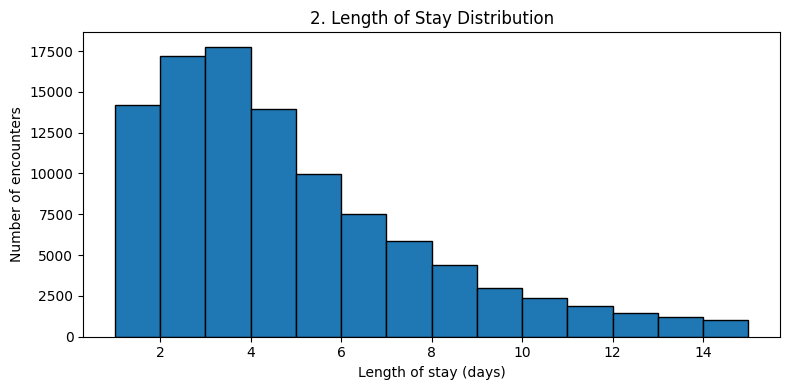

In [51]:
plt.figure(figsize=(8, 4))
plt.hist(clean['time_in_hospital'], bins=range(1, int(clean['time_in_hospital'].max()) + 2), edgecolor='black')
plt.title('2. Length of Stay Distribution')
plt.xlabel('Length of stay (days)')
plt.ylabel('Number of encounters')
plt.tight_layout()
plt.savefig('02_length_of_stay.png', dpi=150)
plt.show()

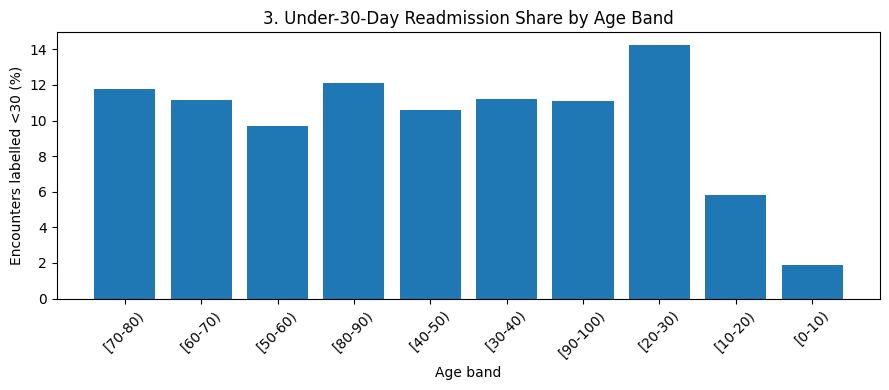

In [52]:
age_chart = age_readmission[~age_readmission['small_group']].dropna(subset=['age_band'])
plt.figure(figsize=(9, 4))
plt.bar(age_chart['age_band'].astype(str), age_chart['readmission_pct'])
plt.title('3. Under-30-Day Readmission Share by Age Band')
plt.xlabel('Age band')
plt.ylabel('Encounters labelled <30 (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('03_readmission_by_age.png', dpi=150)
plt.show()

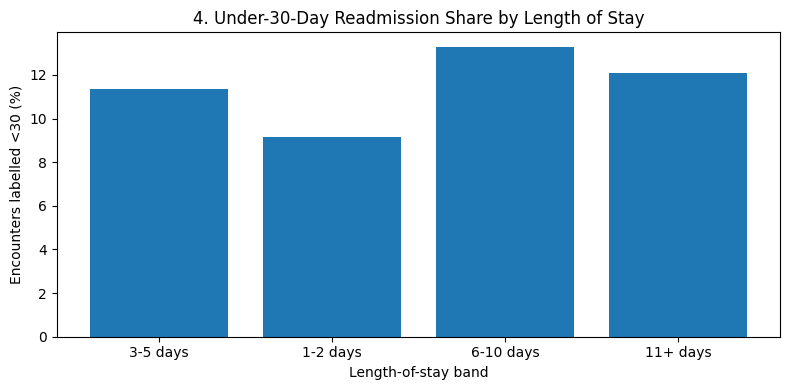

In [53]:
los_chart = los_readmission.dropna(subset=['los_band'])
plt.figure(figsize=(8, 4))
plt.bar(los_chart['los_band'].astype(str), los_chart['readmission_pct'])
plt.title('4. Under-30-Day Readmission Share by Length of Stay')
plt.xlabel('Length-of-stay band')
plt.ylabel('Encounters labelled <30 (%)')
plt.tight_layout()
plt.savefig('04_readmission_by_los.png', dpi=150)
plt.show()

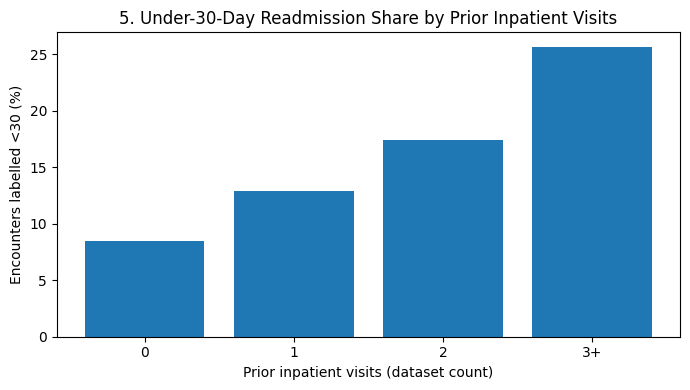

In [54]:
util_chart = prior_inpatient_readmission.dropna(subset=['prior_inpatient_band'])
plt.figure(figsize=(7, 4))
plt.bar(util_chart['prior_inpatient_band'].astype(str), util_chart['readmission_pct'])
plt.title('5. Under-30-Day Readmission Share by Prior Inpatient Visits')
plt.xlabel('Prior inpatient visits (dataset count)')
plt.ylabel('Encounters labelled <30 (%)')
plt.tight_layout()
plt.savefig('05_readmission_by_prior_inpatient_visits.png', dpi=150)
plt.show()

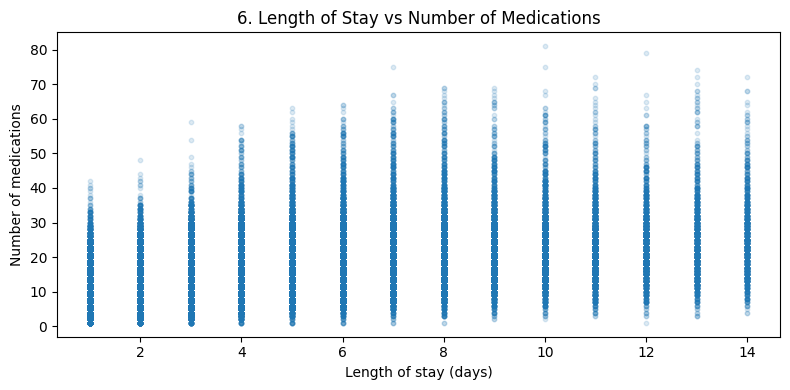

In [55]:
plt.figure(figsize=(8, 4))
plt.scatter(clean['time_in_hospital'], clean['num_medications'], alpha=0.15, s=10)
plt.title('6. Length of Stay vs Number of Medications')
plt.xlabel('Length of stay (days)')
plt.ylabel('Number of medications')
plt.tight_layout()
plt.savefig('06_los_vs_medications.png', dpi=150)
plt.show()

## 13. Conclusions, Recommendations & Limitations
### Conclusions

We can get an insight into a variety of data within the hospital and patient admissions. Trends in the data have been understood and areas that may be worth exploring further have been identified.

### Recommendations

Consider looking at patients who are frequently admitted inpatient and/or emergency departments.
Observe readmission trends to understand common occurrences.
Further investigation into durations of stays within a hospital could improve the management of patients.
Improving data recording in hospitals could create more complete and accurate information.

### Limitations

A few limitations in the analysis are:

The information is from 1999 to 2008, so may not be representative of current hospital practices.
Patients may be seen several times, therefore not every record is independent.
The `readmitted` column does not give an exact time of readmission.
Exact sequences of admissions, or how long patients take to be transferred between places could not be calculated, as times are not provided.
Some comparisons may be affected by missing data and administrative codes.
Correlations between variables have been found, but causal relationships cannot be concluded.
Although this data has been de-identified, care should still be taken when handling healthcare information.

Throughout this project meaningful conclusions have been made from analysing healthcare data using various libraries in Python (Pandas, NumPy and Matplotlib).

In [56]:
overall_readmit = clean['readmitted_30d'].mean() * 100
mean_los = clean['time_in_hospital'].mean()
median_los = clean['time_in_hospital'].median()
top_age = age_readmission.loc[~age_readmission['small_group']].sort_values(
    'readmission_pct', ascending=False
).head(1)
top_los = los_readmission.sort_values('readmission_pct', ascending=False).head(1)

top_age_text = (
    f"{top_age.iloc[0]['age_band']}: {top_age.iloc[0]['readmission_pct']:.1f}%"
    if len(top_age) else 'Not enough group data'
)
top_los_text = (
    f"{top_los.iloc[0]['los_band']}: {top_los.iloc[0]['readmission_pct']:.1f}%"
    if len(top_los) else 'Not enough group data'
)

report = f'''PROJECT 07 - HEALTHCARE READMISSION & PATIENT FLOW
Data source: UCI Diabetes 130-US Hospitals for Years 1999-2008

SUMMARY
Cleaned encounters: {len(clean):,}
Unique de-identified patients: {clean['patient_nbr'].nunique():,}
Mean encounters per patient: {len(clean) / clean['patient_nbr'].nunique():.2f}
Mean length of stay: {mean_los:.2f} days
Median length of stay: {median_los:.2f} days
Encounters labelled <30: {overall_readmit:.2f}%

GROUP PATTERNS
Highest readmission percentage among sufficiently large age groups: {top_age_text}
Highest readmission percentage by length-of-stay group: {top_los_text}

DATA QUALITY
Exact duplicate rows in source: {duplicate_rows:,}
Duplicate encounter IDs observed: {duplicate_encounters:,}
Rows retained after cleaning: {len(clean):,}
Rows excluded by cleaning: {before_rows - len(clean):,}

OPERATIONAL REVIEW IDEAS
1. Review patient-flow processes for groups with longer recorded stays, without assuming that length of stay causes readmission.
2. Examine discharge planning and follow-up workflows as potential areas for a separate, properly designed quality-improvement study.
3. Check administrative code mappings and missingness before comparing departments or admission pathways.
4. Validate any apparent group differences on a more recent, representative dataset.

LIMITATIONS & DISCLAIMER
This is a retrospective descriptive analysis of historical, de-identified data. It does not establish causality, predict an individual's outcome, or provide clinical advice. The dataset's readmission labels are used as supplied; exact time-to-readmission is not reconstructed. Group differences may reflect data quality, access, coding, case mix or other unmeasured factors. No patient-level risk score or clinical decision tool is created.
'''
print(report)

PROJECT 07 - HEALTHCARE READMISSION & PATIENT FLOW
Data source: UCI Diabetes 130-US Hospitals for Years 1999-2008

SUMMARY
Cleaned encounters: 101,766
Unique de-identified patients: 71,518
Mean encounters per patient: 1.42
Mean length of stay: 4.40 days
Median length of stay: 4.00 days
Encounters labelled <30: 11.16%

GROUP PATTERNS
Highest readmission percentage among sufficiently large age groups: [20-30): 14.2%
Highest readmission percentage by length-of-stay group: 6-10 days: 13.3%

DATA QUALITY
Exact duplicate rows in source: 0
Duplicate encounter IDs observed: 0
Rows retained after cleaning: 101,766
Rows excluded by cleaning: 0

OPERATIONAL REVIEW IDEAS
1. Review patient-flow processes for groups with longer recorded stays, without assuming that length of stay causes readmission.
2. Examine discharge planning and follow-up workflows as potential areas for a separate, properly designed quality-improvement study.
3. Check administrative code mappings and missingness before comparin

## 14. Saving Results
All of the information is saved into a new folder.
Within this folder there is

Clean data on patient encounters
Information on quality of the data and missing values
Summarising patient flow and re-admissions
Lengths of stay and frequency of encounters
Sensitivity analyses
Conclusions and limitations of the project
The 6 charts
All of this information can be found in one ZIP file called project07_results.zip.

In [57]:
folder = 'project07_results'
os.makedirs(folder, exist_ok=True)

clean.to_csv(f'{folder}/clean_encounters.csv', index=False)
missing_table.to_csv(f'{folder}/source_missingness_audit.csv')
missing_clean_table.to_csv(f'{folder}/clean_missingness_audit.csv')
flow_summary.to_csv(f'{folder}/patient_flow_summary.csv')
outcome_counts.to_csv(f'{folder}/readmission_outcomes.csv')
los_by_outcome.to_csv(f'{folder}/length_of_stay_by_outcome.csv')
frequency_summary.to_csv(f'{folder}/encounter_frequency_per_patient.csv')
age_readmission.to_csv(f'{folder}/readmission_by_age.csv', index=False)
los_readmission.to_csv(f'{folder}/readmission_by_length_of_stay.csv', index=False)
admission_type_readmission.to_csv(f'{folder}/readmission_by_admission_type.csv', index=False)
admission_source_readmission.to_csv(f'{folder}/readmission_by_admission_source.csv', index=False)
utilisation_summary.to_csv(f'{folder}/utilisation_by_readmission_outcome.csv')
prior_inpatient_readmission.to_csv(f'{folder}/readmission_by_prior_inpatient_visits.csv', index=False)
race_readmission.to_csv(f'{folder}/readmission_by_race_audit.csv', index=False)
gender_readmission.to_csv(f'{folder}/readmission_by_gender_audit.csv', index=False)
sensitivity.to_csv(f'{folder}/sensitivity_analysis.csv', index=False)

with open(f'{folder}/conclusions_and_limitations.txt', 'w', encoding='utf-8') as f:
    f.write(report)

chart_files = [
    '01_readmission_outcomes.png', '02_length_of_stay.png',
    '03_readmission_by_age.png', '04_readmission_by_los.png',
    '05_readmission_by_prior_inpatient_visits.png', '06_los_vs_medications.png'
]
for image_file in chart_files:
    shutil.copy(image_file, folder)

shutil.make_archive(folder, 'zip', folder)
print('Created:', folder + '.zip')
print('Open the Colab Files panel and download the ZIP.')

Created: project07_results.zip
Open the Colab Files panel and download the ZIP.
